# Normal samples from LLM flips: calibration and the CLT

Target: **2,000 samples with mean 10 and standard deviation 2**, each obtained from a fixed group of fresh LLM responses in $\{-1,1\}$. This notebook analyzes recorded calls; it never sends API requests or generates substitute random data. Rerun it after collection finishes to refresh the results.

The model, prompt, settings, provider metadata, retries, invalid responses, and immutable group indices are retained. Calls have separate conversations. That design does **not prove independence** or a stable response distribution. The normal approximation, calibration uncertainty, and diagnostics below are conditional on these assumptions.

Public copy: original numerical replies and grouping are preserved. Provider URLs, private paths, and transport-error details are omitted; public file hashes are recomputed. Run `python prepare_data.py` from the repository root before executing this notebook. See the root README for provenance and reproduction steps.

In [1]:
from pathlib import Path
import hashlib
import json
import math
import numpy as np
import pandas as pd
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

# Works from this notebook's directory, repository root, or experiment directory.
locations = [Path.cwd() / 'llm_randomness',
             Path.cwd() / 'notebooks/llm_randomness', Path.cwd()]
ROOT = next((p for p in locations if (p / 'PLAN.md').exists()), None)
DATA_OVERRIDE = ROOT / 'runs/clt_40_cal160000/data'
if ROOT is None and DATA_OVERRIDE is None:
    raise FileNotFoundError('Run from the repository root or python/notebooks.')
DATA = Path(DATA_OVERRIDE) if DATA_OVERRIDE is not None else ROOT / 'data'
manifest_path = DATA / 'manifest.json'
manifest = json.loads(manifest_path.read_text()) if manifest_path.exists() else {}
N_FLIPS = int(manifest.get('flips_per_sample', 40))
M_CALIBRATION = int(manifest.get('calibration_calls', 1000))
TARGET_SAMPLES = int(manifest.get('requested_samples_per_method', manifest.get('target_samples', 2000)))
assert N_FLIPS > 0 and M_CALIBRATION > 0 and TARGET_SAMPLES > 0
print('Data directory:', DATA)
calibration_pool = manifest.get('calibration_pool') or {}
IMPORTED_CALIBRATION = int(calibration_pool.get('imported_count', 0))
NEW_CALIBRATION = int(calibration_pool.get('new_calibration_calls', M_CALIBRATION))
assert IMPORTED_CALIBRATION + NEW_CALIBRATION == M_CALIBRATION, 'Calibration plan counts mismatch.'
print(f'Plan: {M_CALIBRATION:,} calibration observations '
      f'({IMPORTED_CALIBRATION:,} imported + {NEW_CALIBRATION:,} new); '
      f'{N_FLIPS} new flips per sample; {TARGET_SAMPLES:,} target samples.')
if calibration_pool:
    print('Pooled calibration: earlier compatible observations are reused ONLY for calibration. '
          'All evaluation groups use new production calls.')
    display(calibration_pool)
print('Plain-text formula: X = 10 + 2 * (sum_of_flips - n * (2*p_hat - 1)) '
      '/ sqrt(n * 4*p_hat*(1-p_hat)); p_hat is frozen from calibration.')
print('Approximate calibration contribution to output mean standard error:',
      2*math.sqrt(N_FLIPS/M_CALIBRATION))

def read_records(path):
    if not path.exists():
        return []
    lines = path.read_text().splitlines()
    records = []
    for index, line in enumerate(lines):
        if not line.strip():
            continue
        try:
            records.append(json.loads(line))
        except json.JSONDecodeError:
            if index == len(lines) - 1:
                print(f'Incomplete final line in {path.name}; refresh after collection.')
            else:
                raise
    return records

columns = ['request_id', 'phase', 'prompt_id', 'prompt', 'group_id', 'position',
           'planned_index', 'raw_response', 'value', 'valid', 'status', 'provider_response_id',
           'model', 'system_fingerprint', 'started_at_utc', 'finished_at_utc',
           'elapsed_seconds', 'usage', 'record_type', 'calibration_source_run',
           'original_phase', 'original_request_id']
raw = pd.DataFrame(read_records(DATA / 'responses.jsonl')).reindex(columns=columns)
attempts = pd.DataFrame(read_records(DATA / 'attempts.jsonl'))
assert not raw.request_id.duplicated().any(), 'Duplicate terminal request IDs.'
raw['valid'] = raw.valid.fillna(False).astype(bool)
raw['value'] = pd.to_numeric(raw.value, errors='coerce')
raw['group_id'] = pd.to_numeric(raw.group_id, errors='coerce')
raw['position'] = pd.to_numeric(raw.position, errors='coerce')
raw['planned_index'] = pd.to_numeric(raw.planned_index, errors='coerce')
raw['parsed_binary_valid'] = raw.valid & raw.value.isin([-1, 1])
print(f'Snapshot: {len(raw):,} response records (including any imported calibration); '
      f'{len(attempts):,} HTTP attempts recorded in this run.')
print('Manifest available:', bool(manifest))
display({k: manifest.get(k) for k in ['status', 'settings', 'endpoint', 'target_mean',
    'target_standard_deviation', 'selection', 'calibration', 'terminal_calls']})
display(pd.DataFrame([dict(phase=name, **{k:v for k,v in phase.items()
    if k != 'selected_group_ids'}) for name,phase in manifest.get('phases', {}).items()]))

# Verify supplied completion hashes; partial collections may not yet have hashes.
hash_map = manifest.get('file_sha256', {})
if not isinstance(hash_map, dict):
    hash_map = {}
checked = []
for name, expected in hash_map.items():
    if isinstance(expected, dict):
        expected = expected.get('sha256')
    if not isinstance(expected, str):
        continue
    path = DATA / Path(name).name
    if path.exists():
        actual = hashlib.sha256(path.read_bytes()).hexdigest()
        assert actual == expected, f'Hash mismatch: {path}'
        checked.append(path.name)
print('Verified manifest SHA-256:', checked or 'none supplied for available files')

Data directory: <repository>/notebooks/llm_randomness/runs/clt_40_cal160000/data
Plan: 160,000 calibration observations (91,042 imported + 68,958 new); 40 new flips per sample; 2,000 target samples.
Pooled calibration: earlier compatible observations are reused ONLY for calibration. All evaluation groups use new production calls.


{'source_summary': '../../../calibration_pool/summary.json',
 'summary_sha256': '3ba3de02b4dbaa59a804b2b9189860ebe05a06486440077921c9f831a6681c95',
 'csv_sha256': 'cea3375b274e308b74b0a525244d3c4a48a08f261be929a35001feffc5044bc6',
 'imported_count': 91042,
 'new_calibration_calls': 68958,
 'csv_snapshot': 'calibration_pool_snapshot.csv',
 'summary_snapshot': 'calibration_pool_summary.json'}

Plain-text formula: X = 10 + 2 * (sum_of_flips - n * (2*p_hat - 1)) / sqrt(n * 4*p_hat*(1-p_hat)); p_hat is frozen from calibration.
Approximate calibration contribution to output mean standard error: 0.03162277660168379


Snapshot: 240,000 response records (including any imported calibration); 148,991 HTTP attempts recorded in this run.
Manifest available: True


{'status': 'complete',
 'settings': {'model': 'gpt-4.1-mini',
  'temperature': 1.0,
  'top_p': 1.0,
  'max_tokens': 32,
  'n': 1,
  'stream': False},
 'endpoint': '[private provider endpoint omitted]',
 'target_mean': 10,
 'target_standard_deviation': 2,
 'selection': {'prompt_id': 'binary_11',
  'prompt': 'Pick one at random: B or A. Respond with only the letter.',
  'pilot_n': 100,
  'pilot_valid': 100,
  'pilot_plus': 53,
  'pilot_p': 0.53},
 'calibration': {'p_hat': 0.55051875,
  'mu': 0.10103749999999989,
  'sigma': 0.9948826179975958,
  'valid_count': 160000,
  'plus_count': 88083,
  'target_mean_calibration_standard_error_approx': 0.03162277660168379},
 'terminal_calls': 240000}

,phase,status,calls,valid_calls,accepted_groups,total_groups
0,calibration,complete,160000,160000,NaN,NaN
1,clt,complete,80000,80000,2000.0,2000.0


Verified manifest SHA-256: ['responses.jsonl', 'attempts.jsonl', 'requests_started.jsonl', 'calibration_pool_snapshot.csv', 'calibration_pool_summary.json']


## Prompt selection provenance, then calibration

The original run expanded its pilot adaptively before final calibration: the first eight literal ±1 prompts received 800 calls and had observed $P(+1)\geq0.99$. Those results are retained. Eight additional prompts use binary labels (such as heads/tails, A/B, 0/1, Mary/Ann, or red/blue), with a fixed, recorded mapping from each label to ±1. Every candidate receives 100 pilot calls; no valid result is selectively discarded.

For that original pilot, compare all 16 candidates. Only candidates with 100 valid answers are eligible. Choose the rate closest to 0.50, breaking ties by candidate index. Pilot confidence intervals describe individual candidates; adaptive prompt exploration and selection do not establish that the selected prompt's true probability is 0.50. A follow-up run may inherit this chosen prompt without making new pilot calls; the source manifest and its hash are verified below. Calibration is the only source of the frozen transformation parameters. For a pooled run, the recorded pool reuses earlier compatible calls and adds new calibration calls; evaluation still uses entirely new production calls. The imported observations are not treated as new API requests.

In [2]:
def wilson(k, n):
    if n == 0:
        return (np.nan, np.nan)
    result = stats.binomtest(int(k), int(n)).proportion_ci(method='wilson')
    return (result.low, result.high)

selection_source = manifest.get('selection_source')
if selection_source:
    print('Inherited prompt selection (no new pilot required):')
    display(selection_source)
    source_path = Path(selection_source['source_manifest'])
    if not source_path.is_absolute():
        source_path = DATA / source_path
    assert source_path.exists(), f'Missing inherited selection source: {source_path}'
    source_bytes = source_path.read_bytes()
    assert hashlib.sha256(source_bytes).hexdigest()==selection_source['sha256'], 'Selection-source hash mismatch.'
    source_manifest = json.loads(source_bytes)
    assert source_manifest['selection']==manifest['selection'], 'Inherited selection differs from source.'
    if 'selection' in selection_source:
        assert selection_source['selection']==manifest['selection'], 'Recorded inherited selection mismatch.'
    print('Source manifest hash and inherited selection verified.')
response_mappings = manifest.get('response_mappings', {})
mapping_rows = [dict(prompt_id=prompt_id, response_token=token, mapped_value=value)
                for prompt_id, mapping in response_mappings.items()
                for token, value in mapping.items()]
display(pd.DataFrame(mapping_rows))

# Independently check raw text against the declared parser/mapping. No token
# repair or response-dependent reassignment is permitted here.
binary_records = raw.loc[raw.phase.isin(['binary_pilot','calibration','clt'])]
mapping_checks = []
for row in binary_records.itertuples():
    mapping = response_mappings.get(row.prompt_id, {'1': 1, '+1': 1, '-1': -1})
    normalized = str(row.raw_response).strip().lower()
    independently_parsed = mapping.get(normalized)
    declared_valid = bool(row.valid)
    agrees = ((independently_parsed in [-1, 1] and declared_valid
               and independently_parsed == row.value)
              or (independently_parsed is None and not declared_valid))
    mapping_checks.append(dict(request_id=row.request_id, prompt_id=row.prompt_id,
                               raw_response=row.raw_response,
                               independently_parsed=independently_parsed,
                               stored_value=row.value, stored_valid=declared_valid,
                               agrees=agrees))
mapping_audit = pd.DataFrame(mapping_checks)
if len(mapping_audit):
    assert mapping_audit.agrees.all(), 'Raw response mapping disagrees with stored data.'
    print(f'Independent raw mapping validated for {len(mapping_audit):,} binary responses.')
    display(mapping_audit.head(20))
else:
    print('No binary responses to validate yet.')

pilot = raw.loc[raw.phase.eq('binary_pilot')].copy()
rows = []
for prompt_id, group in pilot.groupby('prompt_id', sort=False):
    valid = group.loc[group.parsed_binary_valid]
    n, ones = len(valid), int(valid.value.eq(1).sum())
    lo, hi = wilson(ones, n)
    rows.append(dict(prompt_id=prompt_id, prompt=group.prompt.iloc[0],
                     calls=len(group), valid=n, invalid=len(group)-n,
                     ones=ones, p_hat=ones/n if n else np.nan,
                     ci95_low=lo, ci95_high=hi,
                     eligible=len(group)==100 and n==100))
pilot_table = pd.DataFrame(rows)
if len(pilot_table):
    pilot_table['candidate_index'] = pilot_table.prompt_id.str.rsplit('_', n=1).str[-1].astype(int)
    pilot_table['distance_from_half'] = (pilot_table.p_hat-.5).abs()
    pilot_table = pilot_table.sort_values('candidate_index')
display(pilot_table)
print('Recorded prompt selection:', manifest.get('selection', 'not yet available'))
if len(pilot_table):
    eligible = pilot_table.loc[pilot_table.eligible].sort_values(
        ['distance_from_half','candidate_index'])
    print('Eligible candidates ordered by distance from 0.50, then candidate index:')
    display(eligible[['candidate_index','prompt_id','p_hat','distance_from_half']])
    selection = manifest.get('selection') or {}
    if len(pilot_table)==16 and len(eligible) and selection.get('prompt_id'):
        assert eligible.iloc[0].prompt_id == selection['prompt_id'], 'Selection rule mismatch.'
        print('Recorded selection independently matches the full 16-candidate pilot rule.')
if len(pilot):
    display(pilot[['request_id', 'prompt_id', 'raw_response', 'value', 'valid',
                   'model', 'provider_response_id']].head(20))
else:
    print('No new pilot calls: inherited prompt selection.' if selection_source
          else 'No pilot responses recorded yet.')
if len(pilot):
    pilot.to_csv(DATA / 'binary_pilot_calls.csv', index=False)
    pilot_table.to_csv(DATA / 'binary_pilot_summary.csv', index=False)

Inherited prompt selection (no new pilot required):


{'source_manifest': '../../../data/manifest.json',
 'sha256': 'aa876966dba2877f8fb72ed72e5477b6a63b95b4b097fbbe3f98e19b9e5703fa',
 'description': 'Prompt inherited; explicitly pooled historical replies are calibration only'}

Source manifest hash and inherited selection verified.


,prompt_id,response_token,mapped_value
0,binary_0,-1,-1
1,binary_0,1,1
2,binary_1,-1,-1
3,binary_1,1,1
4,binary_2,-1,-1
5,binary_2,1,1
6,binary_3,-1,-1
7,binary_3,1,1
8,binary_4,-1,-1
9,binary_4,1,1


Independent raw mapping validated for 240,000 binary responses.


,request_id,prompt_id,raw_response,independently_parsed,stored_value,stored_valid,agrees
0,calibration:binary_11:00000000,binary_11,A,-1,-1,True,True
1,calibration:binary_11:00000001,binary_11,A,-1,-1,True,True
2,calibration:binary_11:00000002,binary_11,B,1,1,True,True
3,calibration:binary_11:00000003,binary_11,A,-1,-1,True,True
4,calibration:binary_11:00000004,binary_11,B,1,1,True,True
5,calibration:binary_11:00000005,binary_11,B,1,1,True,True
6,calibration:binary_11:00000006,binary_11,A,-1,-1,True,True
7,calibration:binary_11:00000007,binary_11,B,1,1,True,True
8,calibration:binary_11:00000008,binary_11,B,1,1,True,True
9,calibration:binary_11:00000009,binary_11,B,1,1,True,True


""


Recorded prompt selection: {'prompt_id': 'binary_11', 'prompt': 'Pick one at random: B or A. Respond with only the letter.', 'pilot_n': 100, 'pilot_valid': 100, 'pilot_plus': 53, 'pilot_p': 0.53}
No new pilot calls: inherited prompt selection.


## Calibration and its uncertainty

For $p=P(Y=1)$, $\mu=2p-1$ and $\sigma^2=4p(1-p)$. Freeze estimates from $m$ calibration observations. The manifest specifies whether these are all new or a declared pool of imported and new calls. An $n$-flip group with sum $S$ becomes

$$Z=\frac{S-n(2\hat p-1)}{\sqrt{n\,4\hat p(1-\hat p)}},\qquad X=10+2Z.$$

Plain text: subtract n times the calibrated flip mean from the sum, divide by sqrt(n) times the calibrated flip standard deviation, then multiply by 2 and add 10.

The calibration estimate is shared by all generated samples. Its error causes a common shift and scaling error; generating more output samples does not eliminate it. The approximate standard error contributed to the generated distribution's mean is $2\sqrt{n/m}$: **0.4 for 40 flips and 1,000 calibration calls; 0.2 for 100 flips and 10,000 calibration calls**. For 40 flips and 160,000 calibration observations this is about **0.0316**, or ±0.062 at 95%. The first two plans correspond to about ±0.78 and ±0.39 at 95%, respectively. These precision estimates assume independent observations from one stable distribution. Pooling across time or routing can invalidate that assumption, even if the nominal sample count is large. This is separate from the finite-sample uncertainty of an observed histogram.

We require all planned calibration records to be valid before transforming production data. No per-group or production-wide recentering is applied.

In [3]:
calibration = raw.loc[raw.phase.eq('calibration')].copy()
calibration['calibration_origin'] = np.where(
    calibration.record_type.eq('imported_calibration'), 'imported', 'new')
imported_calibration = calibration.loc[calibration.calibration_origin.eq('imported')]
new_calibration = calibration.loc[calibration.calibration_origin.eq('new')]
assert len(imported_calibration) <= IMPORTED_CALIBRATION, 'Too many imported calibration observations.'
assert len(new_calibration) <= NEW_CALIBRATION, 'Too many new calibration observations.'
if len(imported_calibration):
    assert imported_calibration.calibration_source_run.notna().all(), 'Missing imported source run.'
    assert imported_calibration.original_phase.notna().all(), 'Missing imported original phase.'
    assert imported_calibration.original_request_id.notna().all(), 'Missing imported original request ID.'
    assert not imported_calibration.duplicated(
        ['calibration_source_run','original_phase','original_request_id']).any(), 'Duplicate imported observation.'
# Local source snapshots preserve the pool independently of mutable earlier runs.
if calibration_pool.get('csv_snapshot') and calibration_pool.get('summary_snapshot'):
    pool_csv_path = DATA / calibration_pool['csv_snapshot']
    pool_summary_path = DATA / calibration_pool['summary_snapshot']
    assert hashlib.sha256(pool_csv_path.read_bytes()).hexdigest()==calibration_pool['csv_sha256'], 'Pool CSV snapshot hash mismatch.'
    assert hashlib.sha256(pool_summary_path.read_bytes()).hexdigest()==calibration_pool['summary_sha256'], 'Pool summary snapshot hash mismatch.'
    pool_summary = json.loads(pool_summary_path.read_text())
    pool_source = pd.read_csv(pool_csv_path,dtype=str,keep_default_na=False)
    assert len(pool_source)==IMPORTED_CALIBRATION==pool_summary['n'], 'Pool snapshot count mismatch.'
    assert pool_source.provider_response_id.ne('').all(), 'Missing snapshot provider ID.'
    assert not pool_source.provider_response_id.duplicated().any(), 'Duplicate snapshot provider ID.'
    assert int(pool_source.value.astype(int).eq(1).sum())==pool_summary['plus_count'], 'Pool snapshot positive count mismatch.'
    assert pool_summary['csv_sha256']==calibration_pool['csv_sha256'], 'Summary and manifest CSV hashes disagree.'
    assert pool_summary['prompt']==manifest['selection']['prompt'], 'Pool prompt differs from selected prompt.'
    assert pool_summary['settings']==manifest['settings'], 'Pool settings differ from current settings.'
    assert pool_summary['mapping']==response_mappings[manifest['selection']['prompt_id']], 'Pool response mapping mismatch.'
    snapshot_by_id = pool_source.set_index('provider_response_id')
    imported_by_id = imported_calibration.set_index('provider_response_id')
    assert imported_by_id.index.isin(snapshot_by_id.index).all(), 'Imported provider ID absent from snapshot.'
    source_matches = snapshot_by_id.loc[imported_by_id.index]
    provenance_columns = {'calibration_source_run':'source_run',
        'original_phase':'original_phase','original_request_id':'request_id',
        'raw_response':'raw_response','model':'model','system_fingerprint':'system_fingerprint',
        'started_at_utc':'started_at_utc','finished_at_utc':'finished_at_utc'}
    for imported_column, snapshot_column in provenance_columns.items():
        actual = imported_by_id[imported_column].fillna('').astype(str).to_numpy()
        expected = source_matches[snapshot_column].fillna('').astype(str).to_numpy()
        assert (actual==expected).all(), f'Imported provenance differs from snapshot: {imported_column}'
    assert (imported_by_id.value.to_numpy()==source_matches.value.astype(int).to_numpy()).all(), 'Imported value differs from snapshot.'
    print('Pool snapshots hashed and imported raw values/provenance independently matched by provider ID.')
origin_rows = []
for origin, frame in calibration.groupby('calibration_origin',sort=True):
    valid = frame.loc[frame.parsed_binary_valid]
    n, ones = len(valid), int(valid.value.eq(1).sum())
    lo, hi = wilson(ones,n)
    origin_rows.append(dict(origin=origin, calls=len(frame), valid=n, invalid=len(frame)-n,
        ones=ones, p_hat=ones/n if n else np.nan, ci95_low=lo, ci95_high=hi))
calibration_origin_rates = pd.DataFrame(origin_rows)
print('Imported versus new calibration observations:')
display(calibration_origin_rates)
if len(calibration_origin_rates):
    calibration_origin_rates.to_csv(DATA / 'calibration_origin_rates.csv',index=False)
source_rows = []
for (source_run, original_phase), frame in imported_calibration.groupby(
        ['calibration_source_run','original_phase'],dropna=False,sort=True):
    valid = frame.loc[frame.parsed_binary_valid]
    n, ones = len(valid), int(valid.value.eq(1).sum())
    lo, hi = wilson(ones,n)
    source_rows.append(dict(source_run=source_run, original_phase=original_phase,
        calls=len(frame), valid=n, ones=ones, p_hat=ones/n if n else np.nan,
        ci95_low=lo, ci95_high=hi))
calibration_source_rates = pd.DataFrame(source_rows)
if len(calibration_source_rates):
    print('Imported calibration by preserved source run and original phase:')
    display(calibration_source_rates)
    calibration_source_rates.to_csv(DATA / 'calibration_source_rates.csv',index=False)
if len(calibration):
    calibration.to_csv(DATA / 'calibration_calls.csv', index=False)
cal_valid = calibration.loc[calibration.parsed_binary_valid]
cal_ready = len(calibration)==M_CALIBRATION and len(cal_valid)==M_CALIBRATION
p_hat = float(cal_valid.value.eq(1).mean()) if len(cal_valid) else np.nan
p_low, p_high = wilson(cal_valid.value.eq(1).sum(), len(cal_valid))
mu = 2*p_hat-1
sigma = math.sqrt(4*p_hat*(1-p_hat)) if np.isfinite(p_hat) else np.nan
cal_ready = cal_ready and 0 < p_hat < 1
cal_summary = pd.DataFrame([dict(calls=len(calibration), valid=len(cal_valid),
    invalid=len(calibration)-len(cal_valid), p_hat=p_hat,
    p_ci95_low=p_low, p_ci95_high=p_high, mu=mu, sigma=sigma,
    variance=sigma**2, ready=cal_ready)])
display(cal_summary)
display(calibration[['request_id', 'prompt_id', 'raw_response', 'value', 'valid',
                     'provider_response_id', 'model', 'system_fingerprint',
                     'started_at_utc', 'finished_at_utc', 'calibration_origin',
                     'calibration_source_run','original_phase','original_request_id']].head(20))
if cal_ready:
    assert len(imported_calibration)==IMPORTED_CALIBRATION, 'Incomplete imported calibration pool.'
    assert len(new_calibration)==NEW_CALIBRATION, 'Incomplete new calibration portion.'
    assert calibration.prompt_id.nunique()==1, 'Calibration has mixed prompts.'
    assert calibration.prompt.nunique()==1, 'Calibration has mixed prompt text.'
    mean_bounds = [10+2*math.sqrt(N_FLIPS)*(p-p_hat)/math.sqrt(p_hat*(1-p_hat))
                   for p in [p_low, p_high]]
    print('Calibration-implied interval for output population mean:', mean_bounds)
    print('Approximate calibration mean-shift SE:', 2*math.sqrt(N_FLIPS/len(cal_valid)))
else:
    print('Calibration incomplete, invalid, or degenerate: transformations withheld.')

Pool snapshots hashed and imported raw values/provenance independently matched by provider ID.
Imported versus new calibration observations:


,origin,calls,valid,invalid,ones,p_hat,ci95_low,ci95_high
0,imported,91042,91042,0,50725,0.55716,0.553932,0.560385
1,new,68958,68958,0,37358,0.54175,0.538029,0.545466


Imported calibration by preserved source run and original phase:


,source_run,original_phase,calls,valid,ones,p_hat,ci95_low,ci95_high
0,completed_40_flip_run,calibration,1000,1000,517,0.517000,0.486022,0.547848
1,completed_40_flip_run,clt,80000,80000,44621,0.557763,0.554318,0.561201
2,stopped_100_flip_run,calibration,10000,10000,5561,0.556100,0.546342,0.565815
3,stopped_100_flip_run,clt,42,42,26,0.619048,0.468140,0.750003


,calls,valid,invalid,p_hat,p_ci95_low,p_ci95_high,mu,sigma,variance,ready
0,160000,160000,0,0.550519,0.54808,0.552955,0.101037,0.994883,0.989791,True


,request_id,prompt_id,raw_response,value,valid,provider_response_id,model,system_fingerprint,started_at_utc,finished_at_utc,calibration_origin,calibration_source_run,original_phase,original_request_id
0,calibration:binary_11:00000000,binary_11,A,-1,True,chatcmpl-EaQQ6S9FECnm8v9s61ikriyoJv5Fb,gpt-4.1-mini-2025-04-14,fp_92f9364fa2,2026-10-18T19:01:13.979161+00:00,2026-10-18T19:01:14.599961+00:00,imported,completed_40_flip_run,calibration,calibration:binary_11:00000000
1,calibration:binary_11:00000001,binary_11,A,-1,True,chatcmpl-EaQQ6ab96aHKCsMN3ST9YzSdslCCb,gpt-4.1-mini-2025-04-14,fp_92f9364fa2,2026-10-18T19:01:13.995288+00:00,2026-10-18T19:01:14.646688+00:00,imported,completed_40_flip_run,calibration,calibration:binary_11:00000001
2,calibration:binary_11:00000002,binary_11,B,1,True,chatcmpl-EaQQ65lHYiRO1pY0dtHgVcmsXXnQM,gpt-4.1-mini-2025-04-14,fp_92f9364fa2,2026-10-18T19:01:13.995606+00:00,2026-10-18T19:01:14.884255+00:00,imported,completed_40_flip_run,calibration,calibration:binary_11:00000002
3,calibration:binary_11:00000003,binary_11,A,-1,True,chatcmpl-EaQQ6dFz00kKblu3vYonarE1WIXoD,gpt-4.1-mini-2025-04-14,fp_8957c4f4dd,2026-10-18T19:01:13.995819+00:00,2026-10-18T19:01:14.626807+00:00,imported,completed_40_flip_run,calibration,calibration:binary_11:00000003
4,calibration:binary_11:00000004,binary_11,B,1,True,chatcmpl-EaQQ6VJ1BnJaKopwudjq7sECGSw22,gpt-4.1-mini-2025-04-14,fp_92f9364fa2,2026-10-18T19:01:13.996036+00:00,2026-10-18T19:01:14.830835+00:00,imported,completed_40_flip_run,calibration,calibration:binary_11:00000004
5,calibration:binary_11:00000005,binary_11,B,1,True,chatcmpl-EaQQ6ptlaSF5csC9lEdsWy05cqWLC,gpt-4.1-mini-2025-04-14,fp_92f9364fa2,2026-10-18T19:01:13.996214+00:00,2026-10-18T19:01:14.716335+00:00,imported,completed_40_flip_run,calibration,calibration:binary_11:00000005
6,calibration:binary_11:00000006,binary_11,A,-1,True,chatcmpl-EaQQ6J9vIZqCgWOv3y8rCccSAL7eJ,gpt-4.1-mini-2025-04-14,fp_8957c4f4dd,2026-10-18T19:01:13.996378+00:00,2026-10-18T19:01:14.486168+00:00,imported,completed_40_flip_run,calibration,calibration:binary_11:00000006
7,calibration:binary_11:00000007,binary_11,B,1,True,chatcmpl-EaQQ6SP3cEAA6nJJIu5ZBPsoqtVek,gpt-4.1-mini-2025-04-14,fp_92f9364fa2,2026-10-18T19:01:13.996568+00:00,2026-10-18T19:01:14.844582+00:00,imported,completed_40_flip_run,calibration,calibration:binary_11:00000007
8,calibration:binary_11:00000008,binary_11,B,1,True,chatcmpl-EaQQ6wbyfoprAW1hvVEAcv9nTg2Ig,gpt-4.1-mini-2025-04-14,fp_92f9364fa2,2026-10-18T19:01:13.996850+00:00,2026-10-18T19:01:14.757603+00:00,imported,completed_40_flip_run,calibration,calibration:binary_11:00000008
9,calibration:binary_11:00000009,binary_11,B,1,True,chatcmpl-EaQQ60C4Hp6dYikj065nUAyl4xX0i,gpt-4.1-mini-2025-04-14,fp_8957c4f4dd,2026-10-18T19:01:13.997028+00:00,2026-10-18T19:01:14.507910+00:00,imported,completed_40_flip_run,calibration,calibration:binary_11:00000009


Calibration-implied interval for output population mean: [9.937990391546665, 10.061947925308424]
Approximate calibration mean-shift SE: 0.03162277660168379


## Production provenance and all intermediate flips

Group and position indices are assigned before dispatch; completion order never chooses a group. We retain the first planned number of valid complete groups in group-index order. Each group must contain exactly $n$ records with positions 0 through $n-1$ and planned index $n\times\mathrm{group\_id}+\mathrm{position}$ and all valid binary outputs. Any malformed group is excluded in full, and any replacement is an entirely fresh group. Calibration, pilot, and production requests must be disjoint. In pooled runs, earlier production calls may appear only as imported calibration, with their original provenance retained. All evaluation draws are new: provider response IDs are checked against the entire pooled calibration set, not merely the newly collected calibration portion.

`production` contains every production response, including excluded groups. `flips` contains all $n$ values of every selected group, `request_ids` provides the corresponding call IDs, and `samples` contains sums, standardized values, and the final outputs. Their CSVs are written by this offline notebook when it executes.

In [4]:
production = raw.loc[raw.phase.eq('clt')].copy()
assert not production.record_type.eq('imported_calibration').any(), 'Imported calibration reused as evaluation.'
def known_provider_ids(frame):
    ids = frame.provider_response_id.dropna().astype(str)
    return ids.loc[ids.str.strip().ne('')]
calibration_provider_ids = known_provider_ids(calibration)
production_provider_ids = known_provider_ids(production)
assert set(calibration_provider_ids).isdisjoint(production_provider_ids), 'Production reuses a pooled calibration provider response.'
assert not calibration_provider_ids.duplicated().any(), 'Duplicate provider response in calibration.'
assert not production_provider_ids.duplicated().any(), 'Duplicate provider response in production.'
if calibration_pool:
    assert len(known_provider_ids(calibration.loc[calibration.parsed_binary_valid]))==int(calibration.parsed_binary_valid.sum()), 'Valid pooled calibration observations require provider IDs.'
    assert len(known_provider_ids(production.loc[production.parsed_binary_valid]))==int(production.parsed_binary_valid.sum()), 'Valid pooled-run production responses require provider IDs.'
print('Calibration/production provider ID overlap: 0; '
      f'IDs present for {len(calibration_provider_ids):,}/{len(calibration):,} calibration '
      f'and {len(production_provider_ids):,}/{len(production):,} production records.')
assert set(calibration.request_id).isdisjoint(production.request_id)
assert set(pilot.request_id).isdisjoint(production.request_id)
assert set(pilot.request_id).isdisjoint(calibration.request_id)
assert production.group_id.notna().all(), 'Missing production group IDs.'
assert production.group_id.eq(production.group_id.astype(int)).all(), 'Noninteger group IDs.'
assert production.position.isin(range(N_FLIPS)).all(), 'Production positions must be 0 through n-1.'
assert production.planned_index.eq(N_FLIPS*production.group_id+production.position).all(), 'Planned index mismatch.'
assert not production.planned_index.duplicated().any(), 'Duplicate production planned indices.'
if len(production) and len(calibration):
    assert set(production.prompt_id) == set(calibration.prompt_id), 'Prompt changed.'
    assert set(production.prompt) == set(calibration.prompt), 'Prompt text changed.'

group_rows = []
for group_id, group in production.groupby('group_id', sort=True):
    pos = set(group.position)
    positions_ok = pos == set(range(N_FLIPS))
    complete = len(group)==N_FLIPS and group.position.nunique()==N_FLIPS and positions_ok
    valid = complete and group.parsed_binary_valid.all()
    group_rows.append(dict(group_id=int(group_id), calls=len(group),
                          valid_calls=int(group.parsed_binary_valid.sum()),
                          complete=complete, accepted=bool(valid)))
group_audit = pd.DataFrame(group_rows, columns=['group_id','calls','valid_calls',
                                              'complete','accepted'])
accepted_ids = group_audit.loc[group_audit.accepted, 'group_id'].head(TARGET_SAMPLES).tolist()
clt_phase = manifest.get('phases', {}).get('clt', {})
if manifest.get('status')=='complete' or clt_phase.get('status')=='complete':
    assert cal_ready, 'Completed collection requires valid, complete calibration.'
    assert len(accepted_ids)==TARGET_SAMPLES, 'Completed CLT collection must have the planned selected groups.'
    assert accepted_ids==clt_phase.get('selected_group_ids'), 'Selected group IDs differ from manifest.'
    print('Completed-manifest CLT group count and selection independently verified.')
selected = production.loc[production.group_id.isin(accepted_ids)].copy()
selected = selected.sort_values(['group_id', 'position'])
assert not selected.request_id.duplicated().any()
flips = selected.pivot(index='group_id', columns='position', values='value')
request_ids = selected.pivot(index='group_id', columns='position', values='request_id')
flips.columns = [f'flip_{int(p):02d}' for p in flips.columns]
request_ids.columns = [f'request_{int(p):02d}' for p in request_ids.columns]
if len(flips):
    assert flips.shape[1] == N_FLIPS and flips.notna().all().all()
    flips = flips.astype(int)
samples = pd.DataFrame(index=flips.index)
if cal_ready and len(flips):
    samples['ones'] = flips.eq(1).sum(axis=1)
    samples['sum_y'] = flips.sum(axis=1)
    samples['z'] = (samples.sum_y-N_FLIPS*mu)/(math.sqrt(N_FLIPS)*sigma)
    samples['x'] = 10+2*samples.z
    samples['calibration_p_hat'] = p_hat
    samples['n_flips'] = N_FLIPS
print(f'{len(production):,} production calls; {len(accepted_ids):,}/{TARGET_SAMPLES:,} selected groups.')
print('Request IDs are unique and disjoint across pilot/calibration/production.')
display(group_audit.head(20))
display(production[['request_id','group_id','position','raw_response','value','valid',
                    'model','system_fingerprint','provider_response_id']].head(20))
with pd.option_context('display.max_columns', 45):
    display(flips.head(10))
display(samples.head(20))
if len(production):
    DATA.mkdir(exist_ok=True)
    production.to_csv(DATA / 'clt_raw_flips.csv', index=False)
    group_audit.to_csv(DATA / 'clt_group_audit.csv', index=False)
if len(flips):
    flips.join(request_ids).to_csv(DATA / 'clt_flips_wide.csv')
if len(samples.columns):
    samples.join(request_ids).to_csv(DATA / 'clt_sample_intermediates.csv')

Calibration/production provider ID overlap: 0; IDs present for 160,000/160,000 calibration and 80,000/80,000 production records.


Completed-manifest CLT group count and selection independently verified.
80,000 production calls; 2,000/2,000 selected groups.
Request IDs are unique and disjoint across pilot/calibration/production.


,group_id,calls,valid_calls,complete,accepted
0,0,40,40,True,True
1,1,40,40,True,True
2,2,40,40,True,True
3,3,40,40,True,True
4,4,40,40,True,True
5,5,40,40,True,True
6,6,40,40,True,True
7,7,40,40,True,True
8,8,40,40,True,True
9,9,40,40,True,True


,request_id,group_id,position,raw_response,value,valid,model,system_fingerprint,provider_response_id
160000,clt:binary_11:00000026,0.0,26,B,1,True,gpt-4.1-mini-2025-04-14,fp_8957c4f4dd,chatcmpl-EaUFYpjAN350bRJrbGTVRynkdCORj
160001,clt:binary_11:00000004,0.0,4,B,1,True,gpt-4.1-mini-2025-04-14,fp_92f9364fa2,chatcmpl-EaUFY8QNGHS222wBZ3Q8DpokCEZHN
160002,clt:binary_11:00000054,1.0,14,A,-1,True,gpt-4.1-mini-2025-04-14,fp_92f9364fa2,chatcmpl-EaUFYREmZOXnTaYSQ34EZ8biX1whN
160003,clt:binary_11:00000006,0.0,6,B,1,True,gpt-4.1-mini-2025-04-14,fp_92f9364fa2,chatcmpl-EaUFYhHOuC7QdZ9VzJL2qawI2ZWWQ
160004,clt:binary_11:00000015,0.0,15,B,1,True,gpt-4.1-mini-2025-04-14,fp_92f9364fa2,chatcmpl-EaUFY29SXsncPbDF08AJSUDkE3K7L
160005,clt:binary_11:00000041,1.0,1,A,-1,True,gpt-4.1-mini-2025-04-14,fp_8957c4f4dd,chatcmpl-EaUFYw9CvY8VuLU2crKOU9X6FQEhA
160006,clt:binary_11:00000037,0.0,37,B,1,True,gpt-4.1-mini-2025-04-14,fp_92f9364fa2,chatcmpl-EaUFYg5hL7h6E6eKxxCy2Roz6oxjd
160007,clt:binary_11:00000022,0.0,22,A,-1,True,gpt-4.1-mini-2025-04-14,fp_8957c4f4dd,chatcmpl-EaUFYeCvT7B5KdLqrFm1c3v6wjzBz
160008,clt:binary_11:00000040,1.0,0,B,1,True,gpt-4.1-mini-2025-04-14,fp_8957c4f4dd,chatcmpl-EaUFYSZNoxFRXqyVw0H35AIFHpYcN
160009,clt:binary_11:00000033,0.0,33,B,1,True,gpt-4.1-mini-2025-04-14,fp_92f9364fa2,chatcmpl-EaUFYRfY6XAAaqq4YaAGbnnpDMe8e


,flip_00,flip_01,flip_02,flip_03,flip_04,flip_05,flip_06,flip_07,flip_08,flip_09,flip_10,flip_11,flip_12,flip_13,flip_14,flip_15,flip_16,flip_17,flip_18,flip_19,flip_20,flip_21,flip_22,flip_23,flip_24,flip_25,flip_26,flip_27,flip_28,flip_29,flip_30,flip_31,flip_32,flip_33,flip_34,flip_35,flip_36,flip_37,flip_38,flip_39
group_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0.0,-1,-1,-1,1,1,1,1,1,-1,-1,-1,1,-1,1,1,1,-1,-1,1,1,1,1,-1,1,1,1,1,-1,-1,1,1,1,-1,1,1,1,-1,1,1,1
1.0,1,-1,-1,1,1,-1,-1,-1,1,1,-1,1,-1,1,-1,1,1,-1,1,1,1,-1,1,1,1,1,-1,1,-1,-1,1,-1,1,1,1,-1,1,1,-1,1
2.0,-1,-1,1,1,1,1,1,-1,1,-1,1,-1,1,-1,-1,1,1,1,-1,-1,-1,-1,-1,1,1,-1,-1,1,1,-1,-1,1,1,1,1,1,1,1,1,-1
3.0,-1,1,1,-1,1,1,1,1,1,1,-1,1,1,-1,1,1,-1,1,1,1,1,-1,-1,-1,1,1,-1,1,1,-1,-1,1,1,1,1,1,-1,1,1,1
4.0,-1,1,-1,-1,-1,1,1,1,1,1,1,1,-1,-1,1,-1,-1,-1,1,-1,1,-1,1,1,-1,-1,-1,1,-1,1,1,-1,-1,1,-1,-1,-1,1,-1,-1
5.0,1,1,-1,-1,-1,-1,-1,-1,1,-1,-1,1,1,-1,-1,1,-1,1,-1,1,-1,-1,1,1,1,-1,-1,1,1,-1,1,-1,1,1,-1,-1,-1,1,1,-1
6.0,1,-1,1,1,-1,-1,1,1,1,1,1,1,1,1,-1,1,1,1,-1,1,1,-1,1,1,1,-1,1,-1,1,-1,-1,1,1,1,-1,1,-1,1,-1,-1
7.0,1,-1,1,1,1,1,-1,-1,1,1,1,1,1,-1,1,1,-1,-1,-1,-1,1,-1,-1,-1,1,1,1,1,-1,1,-1,1,1,-1,1,1,1,1,1,-1
8.0,1,1,1,1,1,1,1,-1,-1,-1,1,1,1,1,-1,1,1,1,-1,-1,1,-1,1,1,1,1,1,1,-1,1,1,1,-1,-1,-1,1,1,1,1,-1


,ones,sum_y,z,x,calibration_p_hat,n_flips
group_id,,,,,,
0.0,26,12,1.264822,12.529644,0.550519,40
1.0,24,8,0.629113,11.258226,0.550519,40
2.0,23,6,0.311259,10.622518,0.550519,40
3.0,28,16,1.900531,13.801061,0.550519,40
4.0,18,-4,-1.278013,7.443974,0.550519,40
5.0,18,-4,-1.278013,7.443974,0.550519,40
6.0,26,12,1.264822,12.529644,0.550519,40
7.0,25,10,0.946968,11.893935,0.550519,40
8.0,28,16,1.900531,13.801061,0.550519,40


In [5]:
# Full dataframes remain available for interactive inspection and filtering.
# Pandas abbreviates long displays; the CSV export contains every row and call ID.
display(flips)
display(request_ids)

,flip_00,flip_01,flip_02,flip_03,flip_04,flip_05,flip_06,flip_07,flip_08,flip_09,...,flip_30,flip_31,flip_32,flip_33,flip_34,flip_35,flip_36,flip_37,flip_38,flip_39
group_id,,,,,,,,,,,,,,,,,,,,,
0.0,-1,-1,-1,1,1,1,1,1,-1,-1,...,1,1,-1,1,1,1,-1,1,1,1
1.0,1,-1,-1,1,1,-1,-1,-1,1,1,...,1,-1,1,1,1,-1,1,1,-1,1
2.0,-1,-1,1,1,1,1,1,-1,1,-1,...,-1,1,1,1,1,1,1,1,1,-1
3.0,-1,1,1,-1,1,1,1,1,1,1,...,-1,1,1,1,1,1,-1,1,1,1
4.0,-1,1,-1,-1,-1,1,1,1,1,1,...,1,-1,-1,1,-1,-1,-1,1,-1,-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995.0,1,1,-1,1,1,1,-1,-1,-1,1,...,1,1,1,-1,1,1,-1,-1,1,1
1996.0,-1,-1,1,-1,-1,1,1,1,1,1,...,1,-1,-1,1,1,1,1,1,-1,1
1997.0,-1,1,1,1,1,1,1,-1,-1,1,...,1,1,1,-1,1,1,-1,-1,1,1


,request_00,request_01,request_02,request_03,request_04,request_05,request_06,request_07,request_08,request_09,...,request_30,request_31,request_32,request_33,request_34,request_35,request_36,request_37,request_38,request_39
group_id,,,,,,,,,,,,,,,,,,,,,
0.0,clt:binary_11:00000000,clt:binary_11:00000001,clt:binary_11:00000002,clt:binary_11:00000003,clt:binary_11:00000004,clt:binary_11:00000005,clt:binary_11:00000006,clt:binary_11:00000007,clt:binary_11:00000008,clt:binary_11:00000009,...,clt:binary_11:00000030,clt:binary_11:00000031,clt:binary_11:00000032,clt:binary_11:00000033,clt:binary_11:00000034,clt:binary_11:00000035,clt:binary_11:00000036,clt:binary_11:00000037,clt:binary_11:00000038,clt:binary_11:00000039
1.0,clt:binary_11:00000040,clt:binary_11:00000041,clt:binary_11:00000042,clt:binary_11:00000043,clt:binary_11:00000044,clt:binary_11:00000045,clt:binary_11:00000046,clt:binary_11:00000047,clt:binary_11:00000048,clt:binary_11:00000049,...,clt:binary_11:00000070,clt:binary_11:00000071,clt:binary_11:00000072,clt:binary_11:00000073,clt:binary_11:00000074,clt:binary_11:00000075,clt:binary_11:00000076,clt:binary_11:00000077,clt:binary_11:00000078,clt:binary_11:00000079
2.0,clt:binary_11:00000080,clt:binary_11:00000081,clt:binary_11:00000082,clt:binary_11:00000083,clt:binary_11:00000084,clt:binary_11:00000085,clt:binary_11:00000086,clt:binary_11:00000087,clt:binary_11:00000088,clt:binary_11:00000089,...,clt:binary_11:00000110,clt:binary_11:00000111,clt:binary_11:00000112,clt:binary_11:00000113,clt:binary_11:00000114,clt:binary_11:00000115,clt:binary_11:00000116,clt:binary_11:00000117,clt:binary_11:00000118,clt:binary_11:00000119
3.0,clt:binary_11:00000120,clt:binary_11:00000121,clt:binary_11:00000122,clt:binary_11:00000123,clt:binary_11:00000124,clt:binary_11:00000125,clt:binary_11:00000126,clt:binary_11:00000127,clt:binary_11:00000128,clt:binary_11:00000129,...,clt:binary_11:00000150,clt:binary_11:00000151,clt:binary_11:00000152,clt:binary_11:00000153,clt:binary_11:00000154,clt:binary_11:00000155,clt:binary_11:00000156,clt:binary_11:00000157,clt:binary_11:00000158,clt:binary_11:00000159
4.0,clt:binary_11:00000160,clt:binary_11:00000161,clt:binary_11:00000162,clt:binary_11:00000163,clt:binary_11:00000164,clt:binary_11:00000165,clt:binary_11:00000166,clt:binary_11:00000167,clt:binary_11:00000168,clt:binary_11:00000169,...,clt:binary_11:00000190,clt:binary_11:00000191,clt:binary_11:00000192,clt:binary_11:00000193,clt:binary_11:00000194,clt:binary_11:00000195,clt:binary_11:00000196,clt:binary_11:00000197,clt:binary_11:00000198,clt:binary_11:00000199
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995.0,clt:binary_11:00079800,clt:binary_11:00079801,clt:binary_11:00079802,clt:binary_11:00079803,clt:binary_11:00079804,clt:binary_11:00079805,clt:binary_11:00079806,clt:binary_11:00079807,clt:binary_11:00079808,clt:binary_11:00079809,...,clt:binary_11:00079830,clt:binary_11:00079831,clt:binary_11:00079832,clt:binary_11:00079833,clt:binary_11:00079834,clt:binary_11:00079835,clt:binary_11:00079836,clt:binary_11:00079837,clt:binary_11:00079838,clt:binary_11:00079839
1996.0,clt:binary_11:00079840,clt:binary_11:00079841,clt:binary_11:00079842,clt:binary_11:00079843,clt:binary_11:00079844,clt:binary_11:00079845,clt:binary_11:00079846,clt:binary_11:00079847,clt:binary_11:00079848,clt:binary_11:00079849,...,clt:binary_11:00079870,clt:binary_11:00079871,clt:binary_11:00079872,clt:binary_11:00079873,clt:binary_11:00079874,clt:binary_11:00079875,clt:binary_11:00079876,clt:binary_11:00079877,clt:binary_11:00079878,clt:binary_11:00079879
1997.0,clt:binary_11:00079880,clt:binary_11:00079881,clt:binary_11:00079882,clt:binary_11:00079883,clt:binary_11:00079884,clt:binary_11:00079885,clt:binary_11:00079886,clt:binary_11:00079887,clt:binary_11:00079888,clt:binary_11:00079889,...,clt:binary_11:00079910,clt:binary_11:00079911,clt:binary_11:00079912,clt:binary_11:00079913,clt:binary_11:00079914,clt:binary_11:00079

## Shape, exact discrete reference, and target normal

The exact conditional reference uses a binomial count $B\sim\mathrm{Binomial}(n,\hat p)$ and the frozen calibration transformation. It is a **plug-in reference**, not proof that the unknown production probability equals $\hat p$. At $p=0.5$, $n$ flips yield only $n+1$ possible output values, spaced $4/\sqrt{n}$ apart at target standard deviation 2: about 0.632 for 40 flips or 0.4 for 100 flips. This is a coarse, bounded normal approximation.

The histogram and Q–Q/ECDF plots compare to the requested continuous $N(10,2^2)$. No fitted normal or post-hoc normalization replaces that target.

,observed,target
n,2000.000000,2000.0
mean,10.088840,10.0
sample_std,2.093129,2.0
min,2.994013,-inf
max,16.343896,inf


,probability,observed,target
0,0.01,5.536848,5.347304
1,0.05,6.808266,6.710293
2,0.25,8.715392,8.651020
3,0.50,9.986809,10.000000
4,0.75,11.258226,11.348980
5,0.95,13.801061,13.289707
6,0.99,15.072479,14.652696


**Recorded result:** mean **10.0888**, standard deviation **2.0931**, versus target **10 and 2**. The production +1 rate is 0.554013, versus frozen calibration 0.551. The bias mismatch shifts the output mean. Under independent flips at the observed production rate, the frozen transform would have standard deviation 1.9985; observed variance is 1.097 times that reference. Departures from this reference require further investigation. Calibration noise, dependence, time variation and backend routing require care; these diagnostics do not identify a cause.

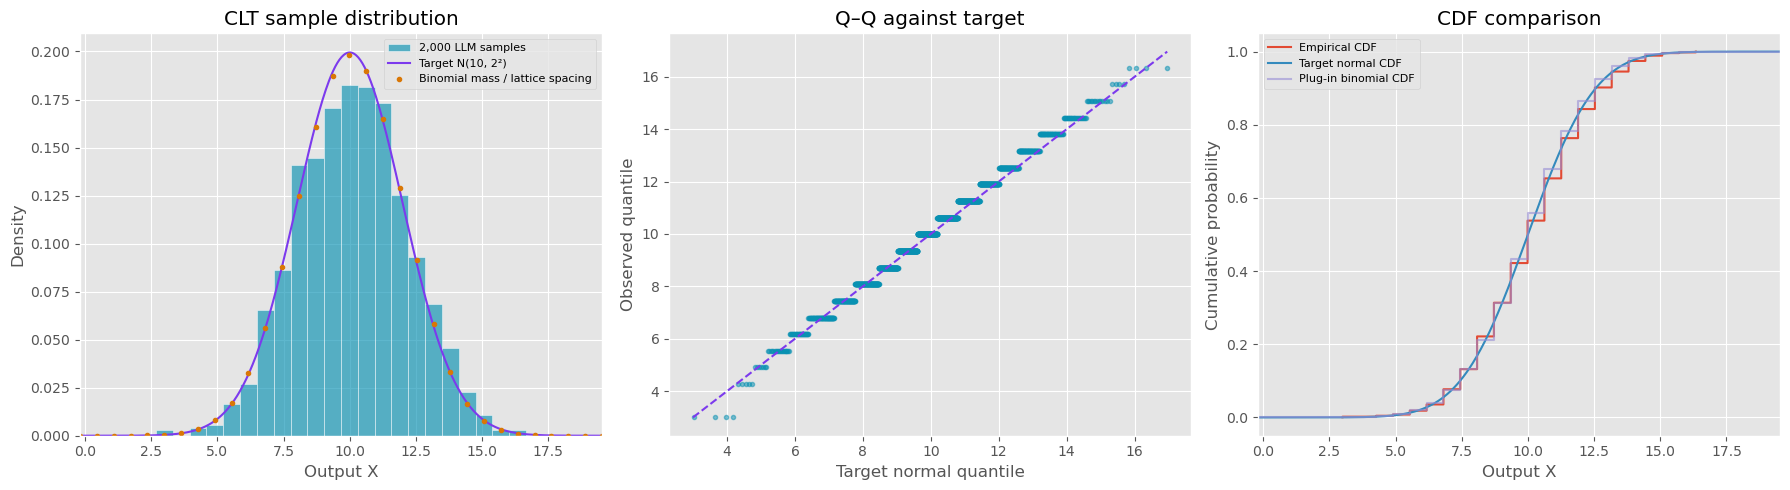

Status: 2,000 samples collected
Lattice spacing: 0.6357086962747651


In [6]:
if 'x' in samples and len(samples):
    x = samples.x.to_numpy()
    probabilities = [0.01,0.05,0.25,0.5,0.75,0.95,0.99]
    summary = pd.DataFrame({'observed': [len(x), np.mean(x), np.std(x,ddof=1),
                                          np.min(x),np.max(x)],
                            'target': [TARGET_SAMPLES,10,2,-np.inf,np.inf]},
                           index=['n','mean','sample_std','min','max'])
    quantiles = pd.DataFrame({'probability': probabilities,
        'observed': np.quantile(x,probabilities),
        'target': stats.norm.ppf(probabilities,loc=10,scale=2)})
    display(summary)
    display(quantiles)
    production_p = float(selected.value.eq(1).mean())
    iid_sd_at_production_p = 2*math.sqrt(production_p*(1-production_p)/(p_hat*(1-p_hat)))
    variance_ratio = float(np.var(x, ddof=1)/iid_sd_at_production_p**2)
    display(Markdown(
        f'**Recorded result:** mean **{np.mean(x):.4f}**, standard deviation '
        f'**{np.std(x,ddof=1):.4f}**, versus target **10 and 2**. '
        f'The production +1 rate is {production_p:.6f}, versus frozen calibration '
        f'{p_hat:.3f}. The bias mismatch shifts the output mean. Under independent '
        f'flips at the observed production rate, the frozen transform would have '
        f'standard deviation {iid_sd_at_production_p:.4f}; observed variance is '
        f'{variance_ratio:.3f} times that reference. Departures from this reference '
        f'require further investigation. Calibration noise, dependence, time variation and '
        f'backend routing require care; these diagnostics do not identify a cause.'))
    summary.to_csv(DATA / 'clt_sample_summary.csv', index_label='statistic')
    quantiles.to_csv(DATA / 'clt_sample_quantiles.csv', index=False)
    counts = np.arange(N_FLIPS+1)
    lattice = 10+2*((2*counts-N_FLIPS)-N_FLIPS*mu)/(math.sqrt(N_FLIPS)*sigma)
    mass = stats.binom.pmf(counts,N_FLIPS,p_hat)
    spacing = lattice[1]-lattice[0]
    visible = lattice[mass>1e-7]
    lo, hi = min(x.min(),visible.min(),3), max(x.max(),visible.max(),17)
    grid = np.linspace(lo,hi,500)
    with plt.style.context('ggplot'):
        fig, axes = plt.subplots(1,3,figsize=(18,5))
        edges = np.r_[lattice-spacing/2,lattice[-1]+spacing/2]
        axes[0].hist(x,bins=edges,density=True,color='#0891b2',alpha=.65,
                     edgecolor='white',label=f'{len(x):,} LLM samples')
        axes[0].plot(grid,stats.norm.pdf(grid,10,2),color='#7c3aed',label='Target N(10, 2²)')
        axes[0].plot(lattice,mass/spacing,'o',markersize=3,color='#d97706',
                     label='Binomial mass / lattice spacing')
        axes[0].set(xlim=(lo,hi),xlabel='Output X',ylabel='Density',title='CLT sample distribution')
        axes[0].legend(fontsize=8)
        ordered = np.sort(x)
        plotting_positions = (np.arange(len(x))+.5)/len(x)
        theoretical = stats.norm.ppf(plotting_positions,10,2)
        axes[1].plot(theoretical,ordered,'.',alpha=.5,color='#0891b2')
        limits = [min(theoretical.min(),ordered.min()),max(theoretical.max(),ordered.max())]
        axes[1].plot(limits,limits,'--',color='#7c3aed')
        axes[1].set(xlabel='Target normal quantile',ylabel='Observed quantile',title='Q–Q against target')
        axes[2].step(ordered,np.arange(1,len(x)+1)/len(x),where='post',label='Empirical CDF')
        axes[2].plot(grid,stats.norm.cdf(grid,10,2),label='Target normal CDF')
        axes[2].step(lattice,np.cumsum(mass),where='post',alpha=.6,label='Plug-in binomial CDF')
        axes[2].set(xlim=(lo,hi),xlabel='Output X',ylabel='Cumulative probability',title='CDF comparison')
        axes[2].legend(fontsize=8)
        fig.tight_layout()
        fig.savefig(DATA / 'clt_normal_diagnostics.png', dpi=180, bbox_inches='tight')
        plt.show()
    print('Status:', f'{TARGET_SAMPLES:,} samples collected' if len(x)==TARGET_SAMPLES else 'PARTIAL COLLECTION')
    print('Lattice spacing:', spacing)
else:
    print('No transformed samples available yet. No synthetic histogram is substituted.')

## Stability and dependence diagnostics

Compare calibration with production, examine consecutive blocks in **planned request order**, and report lag correlations for flips and final outputs. These are exploratory checks, not proofs of independence. A narrow confidence interval assumes independent Bernoulli observations. Invalid-group exclusion can itself select a different distribution, so all-valid-response and selected-group rates are both shown. Provider completion times are provenance, not the sequence used for analysis. The model and system fingerprint tables below expose routing strata: mixing backend configurations can violate an identical-distribution assumption. Fingerprints do not identify all possible backend differences, and matching fingerprints do not establish independence. Within-group fingerprint counts describe how often the calls in each group span recorded configurations.

,source,n,ones,p_hat,ci95_low,ci95_high
0,calibration,160000,88083,0.550519,0.548080,0.552955
1,all production valid responses,80000,44321,0.554013,0.550566,0.557454
2,selected complete groups,80000,44321,0.554013,0.550566,0.557454


Calibration and production response rates by recorded model/fingerprint:


,phase,model,system_fingerprint,calls,valid,invalid,ones,p_hat,ci95_low,ci95_high
0,calibration,gpt-4.1-mini-2025-04-14,fp_92f9364fa2,117439,117439,0,63156,0.537777,0.534924,0.540627
1,calibration,gpt-4.1-mini-2025-04-14,fp_8957c4f4dd,42561,42561,0,24927,0.585677,0.580990,0.590349
2,production,gpt-4.1-mini-2025-04-14,fp_8957c4f4dd,15765,15765,0,9676,0.613765,0.606138,0.621336
3,production,gpt-4.1-mini-2025-04-14,fp_92f9364fa2,64235,64235,0,34645,0.539348,0.535491,0.543200


Per-group routing provenance, ordered by immutable group ID:


,group_id,calls,known_fingerprints,missing_fingerprints,models,selected,fingerprints
0,0,40,2,0,1,True,fp_8957c4f4dd | fp_92f9364fa2
1,1,40,2,0,1,True,fp_8957c4f4dd | fp_92f9364fa2
2,2,40,1,0,1,True,fp_8957c4f4dd
3,3,40,1,0,1,True,fp_8957c4f4dd
4,4,40,2,0,1,True,fp_8957c4f4dd | fp_92f9364fa2
...,...,...,...,...,...,...,...
1995,1995,40,2,0,1,True,fp_8957c4f4dd | fp_92f9364fa2
1996,1996,40,2,0,1,True,fp_8957c4f4dd | fp_92f9364fa2
1997,1997,40,2,0,1,True,fp_8957c4f4dd | fp_92f9364fa2
1998,1998,40,2,0,1,True,fp_8957c4f4dd | fp_92f9364fa2


,selected,known_fingerprints,missing_fingerprints,groups
0,True,1,0,1117
1,True,2,0,883


Calibration in sequential 1,000-observation blocks (planned order; pool order may differ from chronology):


,block,calls,valid,first_planned_index,last_planned_index,imported_calls,new_calls,ones,p_hat,ci95_low,ci95_high
0,0,1000,1000,0,999,1000,0,517,0.517,0.486022,0.547848
1,1,1000,1000,1000,1999,1000,0,570,0.570,0.539105,0.600359
2,2,1000,1000,2000,2999,1000,0,563,0.563,0.532074,0.593444
3,3,1000,1000,3000,3999,1000,0,561,0.561,0.530066,0.591467
4,4,1000,1000,4000,4999,1000,0,594,0.594,0.563259,0.624021
...,...,...,...,...,...,...,...,...,...,...,...
155,155,1000,1000,155000,155999,0,1000,543,0.543,0.512019,0.573652
156,156,1000,1000,156000,156999,0,1000,544,0.544,0.513021,0.574642
157,157,1000,1000,157000,157999,0,1000,516,0.516,0.485024,0.546853
158,158,1000,1000,158000,158999,0,1000,537,0.537,0.506012,0.567704


,block,calls,valid,p_hat,ci95_low,ci95_high
0,0,1000,1000,0.583,0.552179,0.613185
1,1,1000,1000,0.566,0.535087,0.596408
2,2,1000,1000,0.562,0.531070,0.592455
3,3,1000,1000,0.543,0.512019,0.573652
4,4,1000,1000,0.514,0.483028,0.544865
...,...,...,...,...,...,...
75,75,1000,1000,0.543,0.512019,0.573652
76,76,1000,1000,0.573,0.542120,0.603321
77,77,1000,1000,0.532,0.501010,0.562745
78,78,1000,1000,0.564,0.533078,0.594432


,lag,flip_pairs,flip_correlation,output_correlation
0,1,79999,0.001887,0.092599
1,2,79998,0.004756,0.082928
2,5,79995,0.003860,0.075603
3,10,79990,0.010658,0.032435
4,40,79960,-0.000746,0.025669
5,100,79900,0.003212,-0.033256


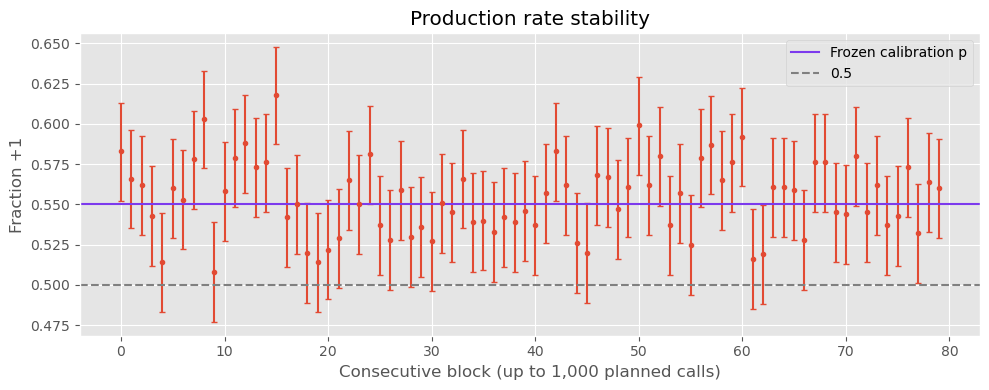

In [7]:
rate_rows = []
for name, frame in [('calibration',calibration),('all production valid responses',production),
                    ('selected complete groups',selected)]:
    valid = frame.loc[frame.parsed_binary_valid]
    ones, n = int(valid.value.eq(1).sum()),len(valid)
    low, high = wilson(ones,n)
    rate_rows.append(dict(source=name,n=n,ones=ones,p_hat=ones/n if n else np.nan,
                          ci95_low=low,ci95_high=high))
display(pd.DataFrame(rate_rows))

routing_rows = []
for phase_name, frame in [('calibration',calibration),('production',production)]:
    for (model, fingerprint), group in frame.groupby(
            ['model','system_fingerprint'],dropna=False,sort=False):
        valid = group.loc[group.parsed_binary_valid]
        n, ones = len(valid), int(valid.value.eq(1).sum())
        lo, hi = wilson(ones,n)
        routing_rows.append(dict(phase=phase_name, model=model,
            system_fingerprint=fingerprint, calls=len(group), valid=n,
            invalid=len(group)-n, ones=ones, p_hat=ones/n if n else np.nan,
            ci95_low=lo, ci95_high=hi))
routing_rates = pd.DataFrame(routing_rows)
print('Calibration and production response rates by recorded model/fingerprint:')
display(routing_rates)

fingerprint_rows = []
for group_id, group in production.groupby('group_id',sort=True):
    known_fingerprints = group.system_fingerprint.dropna().astype(str)
    fingerprint_rows.append(dict(group_id=int(group_id), calls=len(group),
        known_fingerprints=known_fingerprints.nunique(),
        missing_fingerprints=int(group.system_fingerprint.isna().sum()),
        models=group.model.nunique(dropna=True),
        selected=int(group_id) in accepted_ids,
        fingerprints=' | '.join(sorted(known_fingerprints.unique()))))
group_fingerprints = pd.DataFrame(fingerprint_rows)
print('Per-group routing provenance, ordered by immutable group ID:')
display(group_fingerprints)
if len(group_fingerprints):
    display(group_fingerprints.groupby(['selected','known_fingerprints',
                                        'missing_fingerprints']).size().rename('groups').reset_index())
    group_fingerprints.to_csv(DATA / 'clt_group_fingerprints.csv',index=False)
if len(routing_rates):
    routing_rates.to_csv(DATA / 'clt_routing_rates.csv',index=False)

# Fixed 1,000-observation blocks expose calibration drift hidden by an aggregate rate.
# Pooled planned order is import order followed by new calls, not a global time ordering.
ordered_calibration = calibration.sort_values('planned_index').copy()
assert not ordered_calibration.planned_index.duplicated().any(), 'Duplicate calibration indices.'
ordered_calibration['calibration_block'] = ordered_calibration.planned_index//1000
calibration_blocks = []
for block_id, frame in ordered_calibration.groupby('calibration_block',sort=True):
    valid = frame.loc[frame.parsed_binary_valid]
    n, ones = len(valid), int(valid.value.eq(1).sum())
    lo, hi = wilson(ones,n)
    calibration_blocks.append(dict(block=int(block_id),calls=len(frame),valid=n,
        first_planned_index=int(frame.planned_index.min()),
        last_planned_index=int(frame.planned_index.max()),
        imported_calls=int(frame.calibration_origin.eq('imported').sum()),
        new_calls=int(frame.calibration_origin.eq('new').sum()),
        ones=ones,p_hat=ones/n if n else np.nan,ci95_low=lo,ci95_high=hi))
calibration_block_rates = pd.DataFrame(calibration_blocks)
print('Calibration in sequential 1,000-observation blocks (planned order; pool order may differ from chronology):')
display(calibration_block_rates)
if len(calibration_block_rates):
    calibration_block_rates.to_csv(DATA / 'calibration_block_rates.csv',index=False)

ordered_prod = production.sort_values(['group_id','position']).copy()
ordered_prod['planned_block'] = np.arange(len(ordered_prod))//1000
blocks = []
for block_id, frame in ordered_prod.groupby('planned_block'):
    valid = frame.loc[frame.parsed_binary_valid]
    n, ones = len(valid),int(valid.value.eq(1).sum())
    lo,hi=wilson(ones,n)
    blocks.append(dict(block=int(block_id),calls=len(frame),valid=n,
                       p_hat=ones/n if n else np.nan,ci95_low=lo,ci95_high=hi))
block_rates=pd.DataFrame(blocks)
display(block_rates)
series = ordered_prod.value.where(ordered_prod.parsed_binary_valid).reset_index(drop=True)
lag_rows=[]
for lag in sorted(set([1,2,5,10,N_FLIPS,100])):
    paired=pd.concat([series,series.shift(lag)],axis=1).dropna()
    flip_corr=paired.iloc[:,0].corr(paired.iloc[:,1]) if len(paired)>2 else np.nan
    sample_corr=samples.x.autocorr(lag) if 'x' in samples and len(samples)>lag+2 else np.nan
    lag_rows.append(dict(lag=lag,flip_pairs=len(paired),flip_correlation=flip_corr,
                         output_correlation=sample_corr))
display(pd.DataFrame(lag_rows))
if len(block_rates):
    with plt.style.context('ggplot'):
        fig,ax=plt.subplots(figsize=(10,4))
        ax.errorbar(block_rates.block,block_rates.p_hat,
                    yerr=[block_rates.p_hat-block_rates.ci95_low,
                          block_rates.ci95_high-block_rates.p_hat],fmt='.',capsize=2)
        if np.isfinite(p_hat):
            ax.axhline(p_hat,color='#7c3aed',label='Frozen calibration p')
        ax.axhline(.5,color='gray',linestyle='--',label='0.5')
        ax.set(xlabel='Consecutive block (up to 1,000 planned calls)',
               ylabel='Fraction +1',title='Production rate stability')
        ax.legend()
        fig.tight_layout()
        plt.show()

## Interpretation

A completed run contains n times the target sample count valid selected production flips, plus the new calibration calls, any imported calibration observations, any new prompt pilot, excluded groups, and transport retries. Imported observations contribute to the statistical calibration count but not the current API-call cost. The manifest specifies n and all planned counts. Inherited prompt selection refers to the preserved original run. A declared calibration pool may reuse compatible historical calibration or production draws solely as calibration; the evaluation groups always use new production draws. Temporal or routing drift between imported calibration, new calibration, and production is not corrected by increasing the pooled sample count. The CSV derivatives preserve request IDs; `responses.jsonl` and `attempts.jsonl` are the original audit records. The manifest records collection settings and progress.

Finite-flip sums may resemble a normal centrally while differing in their tails and discrete support. Calibration error can shift the entire distribution materially. Inspect the actual mean, standard deviation, quantiles, exact binomial reference, and stability diagnostics together; visual resemblance alone cannot establish independent normal sampling.